# Predicting future volatility regimes

The training and metric logic lives in `market_risk.evaluation.evaluate_classifiers`. This notebook analyses its exported Dummy, Logistic Regression and LightGBM predictions from a fresh kernel.

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from market_risk.modelling.dataset import FEATURES, TARGET_COLUMN, load_model_dataset
from market_risk.evaluation.provenance import verify_saved_evaluation

ROOT = Path.cwd().resolve()
if not (ROOT / 'pyproject.toml').exists():
    ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').exists(), 'Run from the repository or notebooks directory.'
df = load_model_dataset()
manifest = verify_saved_evaluation(df, ROOT / 'results')
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True})
print('Verified corrected dataset and evaluation:', manifest['test_years'])

Verified corrected dataset and evaluation: [2022, 2023, 2024, 2025]


In [2]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, roc_curve, precision_recall_curve
from market_risk.evaluation.classification import CLASS_LABELS

folder = ROOT / 'results/classification'
folds = pd.read_csv(folder / 'fold_results.csv')
predictions = pd.read_csv(folder / 'predictions.csv', parse_dates=['date'])
pooled = pd.read_csv(folder / 'pooled_metrics.csv')
confusion_counts = pd.read_csv(folder / 'confusion_matrices.csv')
display(folds)
display(pooled)

,test_year,model,train_size,test_size,train_start,train_end,test_start,test_end,elevated_threshold,stress_threshold,accuracy,macro_f1,stress_precision,stress_recall,stress_f1,stress_support,predicted_stress_count,stress_roc_auc,stress_average_precision
0,2022,Dummy,1336,251,2016-09-06,2021-12-23,2022-01-03,2022-12-30,0.138151,0.248148,0.103586,0.062575,0.000000,0.000000,0.000000,85,0,0.500000,0.338645
1,2022,Logistic Regression,1336,251,2016-09-06,2021-12-23,2022-01-03,2022-12-30,0.138151,0.248148,0.430279,0.278289,0.389908,1.000000,0.561056,85,218,0.583912,0.420386
2,2022,LightGBM,1336,251,2016-09-06,2021-12-23,2022-01-03,2022-12-30,0.138151,0.248148,0.498008,0.349822,0.438202,0.917647,0.593156,85,178,0.702268,0.544676
3,2023,Dummy,1587,250,2016-09-06,2022-12-22,2023-01-03,2023-12-29,0.170875,0.280087,0.840000,0.304348,0.000000,NaN,0.000000,0,0,NaN,NaN
4,2023,Logistic Regression,1587,250,2016-09-06,2022-12-22,2023-01-03,2023-12-29,0.170875,0.280087,0.216000,0.154759,0.000000,NaN,0.000000,0,37,NaN,NaN
5,2023,LightGBM,1587,250,2016-09-06,2022-12-22,2023-01-03,2023-12-29,0.170875,0.280087,0.308000,0.258149,0.000000,NaN,0.000000,0,101,NaN,NaN
6,2024,Dummy,1837,252,2016-09-06,2023-12-21,2024-01-02,2024-12-31,0.166618,0.264915,0.853175,0.306924,0.000000,0.000000,0.000000,5,0,0.500000,0.019841
7,2024,Logistic Regression,1837,252,2016-09-06,2023-12-21,2024-01-02,2024-12-31,0.166618,0.264915,0.730159,0.373716,0.000000,0.000000,0.000000,5,6,0.769231,0.061097
8,2024,LightGBM,1837,252,2016-09-06,2023-12-21,2024-01-02,2024-12-31,0.166618,0.264915,0.746032,0.390075,0.000000,0.000000,0.000000,5,12,0.753846,0.051828
9,2025,Dummy,2089,250,2016-09-06,2024-12-23,2025-01-02,2025-12-31,0.160231,0.256297,0.744000,0.284404,0.000000,0.000000,0.000000,17,0,0.500000,0.068000


,model,count,accuracy,macro_f1,stress_precision,stress_recall,stress_f1,stress_support,predicted_stress_count,stress_roc_auc,stress_average_precision
0,Dummy,1003,0.635095,0.258943,0.000000,0.000000,0.000000,107,0,0.500000,0.106680
1,Logistic Regression,1003,0.515454,0.478487,0.323232,0.897196,0.475248,107,297,0.882145,0.408111
2,LightGBM,1003,0.554337,0.506225,0.278481,0.822430,0.416076,107,316,0.828042,0.351546


## Definitions and denominators

Quantiles and scalers use training data only. Macro-F1 includes all three labels. Stress recall is undefined when a year contains no actual Stress (2023); blank/NaN does not mean missed Stress. ROC-AUC requires both outcomes. Average precision uses the sklearn step-weighted definition and is not labelled trapezoidal PR-AUC.

In [3]:
actual = predictions.loc[predictions['model'].eq('Dummy')]
display(pd.crosstab(actual['test_year'], actual['actual_regime']).reindex(columns=CLASS_LABELS, fill_value=0))
display(folds.groupby('test_year')[['elevated_threshold', 'stress_threshold']].first())

actual_regime,Normal,Elevated,Stress
test_year,,,
2022,26,140,85
2023,210,40,0
2024,215,32,5
2025,186,47,17


,elevated_threshold,stress_threshold
test_year,,
2022,0.138151,0.248148
2023,0.170875,0.280087
2024,0.166618,0.264915
2025,0.160231,0.256297


## Pooled confusion matrices

Dummy predicts the most common training class and is retained as the accuracy reference. Class balancing makes the fitted models more sensitive to rare regimes, at the cost of more alerts.

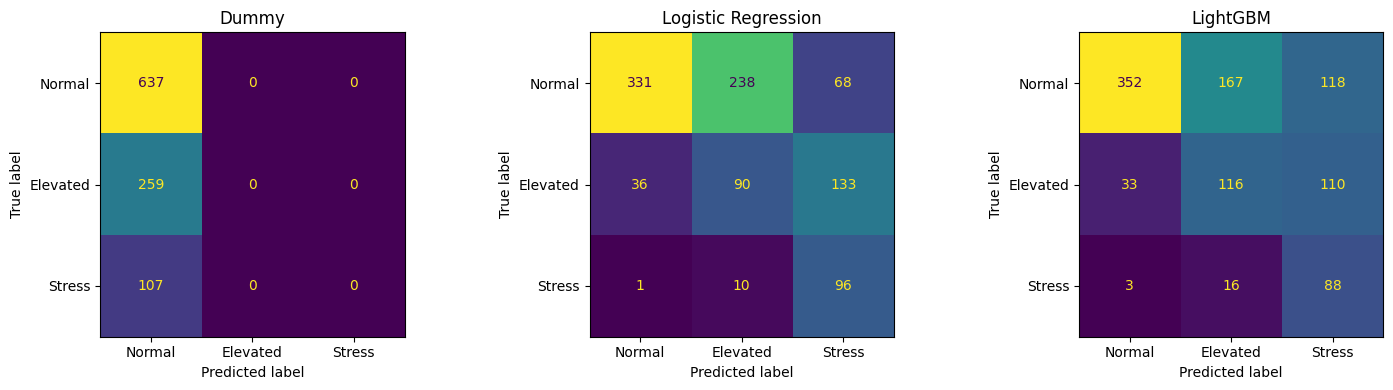

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, group) in zip(axes, predictions.groupby('model', sort=False)):
    matrix = confusion_matrix(group['actual_regime'], group['predicted_regime'], labels=CLASS_LABELS)
    ConfusionMatrixDisplay(matrix, display_labels=CLASS_LABELS).plot(ax=ax, colorbar=False)
    ax.grid(False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

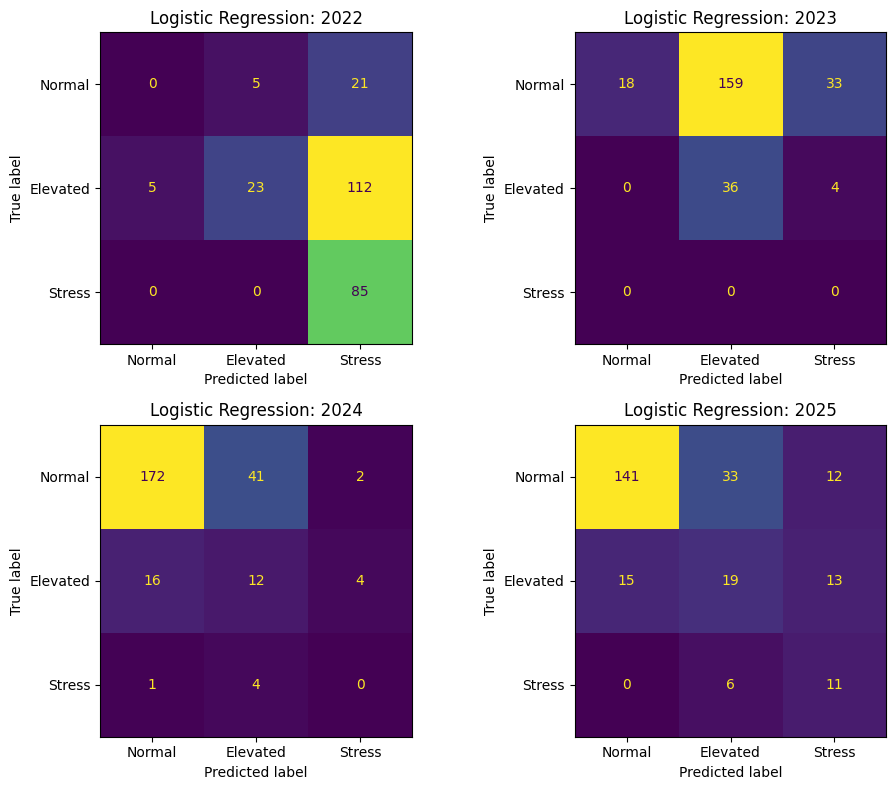

In [5]:
logistic = predictions.loc[predictions['model'].eq('Logistic Regression')]
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (year, group) in zip(axes.flat, logistic.groupby('test_year')):
    matrix = confusion_matrix(group['actual_regime'], group['predicted_regime'], labels=CLASS_LABELS)
    ConfusionMatrixDisplay(matrix, display_labels=CLASS_LABELS).plot(ax=ax, colorbar=False)
    ax.grid(False)
    ax.set_title(f'Logistic Regression: {year}')
plt.tight_layout()
plt.show()

## Stress alerts and misses

Count false alarms as well as detected stress. The unit is an overlapping forecast date, not an independent crisis.

In [6]:
rows = []
for name, group in predictions.groupby('model', sort=False):
    stress = group['actual_regime'].eq('Stress')
    alert = group['predicted_regime'].eq('Stress')
    rows.append({'model': name, 'true_stress_alerts': int((stress & alert).sum()), 'false_stress_alerts': int((~stress & alert).sum()), 'stress_to_normal': int((stress & group['predicted_regime'].eq('Normal')).sum()), 'stress_to_elevated': int((stress & group['predicted_regime'].eq('Elevated')).sum())})
display(pd.DataFrame(rows))
display(logistic.loc[logistic['actual_regime'].eq('Stress') & logistic['predicted_regime'].ne('Stress'), ['date', 'actual_regime', 'predicted_regime', 'prob_stress']])

,model,true_stress_alerts,false_stress_alerts,stress_to_normal,stress_to_elevated
0,Dummy,0,0,107,0
1,Logistic Regression,96,201,1,10
2,LightGBM,88,228,3,16


,date,actual_regime,predicted_regime,prob_stress
1898,2024-07-29,Stress,Elevated,0.185021
1899,2024-07-30,Stress,Elevated,0.216144
1900,2024-07-31,Stress,Normal,0.110237
1901,2024-08-01,Stress,Elevated,0.177310
1902,2024-08-02,Stress,Elevated,0.399661
2548,2025-03-03,Stress,Elevated,0.368761
2566,2025-03-27,Stress,Elevated,0.291583
2567,2025-03-28,Stress,Elevated,0.424465
2568,2025-03-31,Stress,Elevated,0.437744
2569,2025-04-01,Stress,Elevated,0.397115


## Ranking Stress scores

Probability columns are matched using estimator class names. Pooled curves combine annual models with year-specific thresholds; they are descriptive ranking diagnostics, not proof of probability calibration.

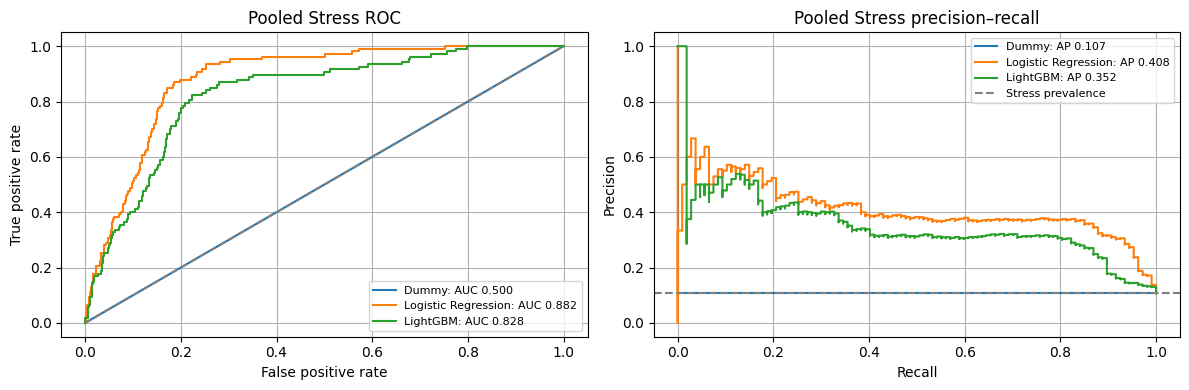

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, group in predictions.groupby('model', sort=False):
    stress = group['actual_regime'].eq('Stress')
    if stress.nunique() < 2:
        continue
    fpr, tpr, _ = roc_curve(stress, group['prob_stress'])
    precision, recall, _ = precision_recall_curve(stress, group['prob_stress'])
    score = pooled.loc[pooled['model'].eq(name)].iloc[0]
    axes[0].plot(fpr, tpr, label=f"{name}: AUC {score['stress_roc_auc']:.3f}")
    axes[1].step(recall, precision, where='post', label=f"{name}: AP {score['stress_average_precision']:.3f}")
axes[0].plot([0, 1], [0, 1], '--', color='grey')
axes[1].axhline(actual['actual_regime'].eq('Stress').mean(), linestyle='--', color='grey', label='Stress prevalence')
axes[0].set(xlabel='False positive rate', ylabel='True positive rate', title='Pooled Stress ROC')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Pooled Stress precision–recall')
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Dummy has the highest pooled accuracy, LightGBM the highest macro-F1, and Logistic Regression the highest Stress recall in this experiment. Both fitted classifiers miss all five Stress dates in 2024. Model preferences depend on error costs; scores have not been calibrated or evaluated in a trading rule. See [classification analysis](../docs/08_classification_analysis.md).